In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

In [2]:
df=pd.read_csv('air_quality.csv')
temp=df.copy() 

#B1 Missing Value Audit


In [3]:
df.shape

(200, 6)

In [4]:
df.head(6)

,temperature,humidity,rainfall,aqi,wind_speed,vehicle_count
0,27.9,48.2,1.71,40.0,1.55,464.0
1,24.7,61.0,NaN,81.2,14.61,614.0
2,16.0,60.5,8.24,221.6,1.20,131.0
3,27.0,56.7,1.62,149.3,16.14,803.0
4,25.8,64.6,4.24,196.7,NaN,190.0
5,36.7,51.8,10.04,NaN,22.69,1391.0


In [5]:
miss_count=df.isnull().sum()
print(miss_count)

temperature      18
humidity         22
rainfall         30
aqi              14
wind_speed       25
vehicle_count    10
dtype: int64


In [6]:
miss_percent=(df.isnull().mean()*100).round(2)
print(miss_percent)

temperature       9.0
humidity         11.0
rainfall         15.0
aqi               7.0
wind_speed       12.5
vehicle_count     5.0
dtype: float64


Rainfall column have highest missing rate and also it has 15 percent miss percent rate so  we can say that no column strictly more than 15 percent missing rate

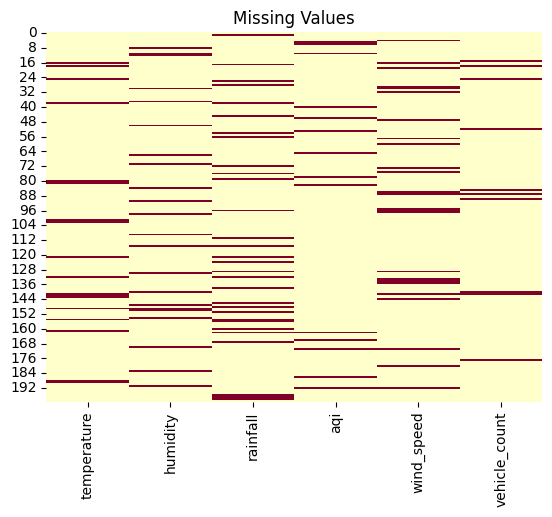

In [7]:
sns.heatmap(df.isnull(), cmap="YlOrRd", cbar=False)
plt.title("Missing Values")
plt.show()

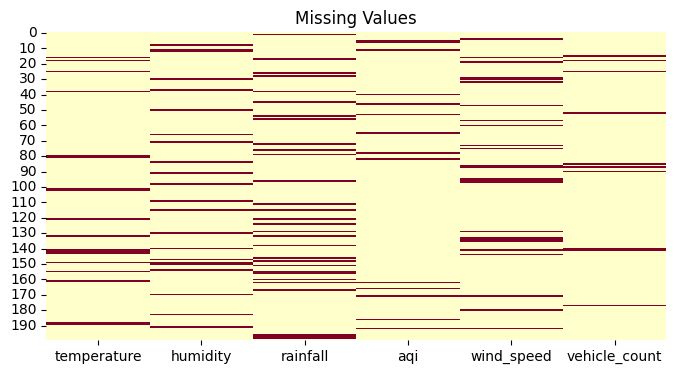

In [8]:
plt.figure(figsize=(8, 4))
sns.heatmap(df.isnull(), cmap="YlOrRd", cbar=False)
plt.title("Missing Values")
plt.show()

Distribution is not systematic and also missing value are scattered

In [9]:
df.describe()

,temperature,humidity,rainfall,aqi,wind_speed,vehicle_count
count,182.000000,178.000000,170.000000,186.000000,175.000000,190.000000
mean,27.769780,64.840449,6.123471,115.859677,11.303429,2830.831579
std,4.574481,11.279858,4.340003,64.368975,22.214313,19617.514249
min,15.300000,38.000000,0.490000,19.200000,1.020000,100.000000
25%,24.625000,57.825000,2.870000,71.825000,1.955000,251.750000
50%,27.900000,64.350000,4.870000,104.000000,3.870000,497.000000
75%,30.600000,72.675000,9.455000,155.675000,10.190000,1129.000000
max,39.900000,95.400000,22.040000,480.900000,207.600000,267588.000000


Column     mean       median     comparison 
Temp       27.76      27.90      median>mean
humidity   64.84      64.35      mean>median
rain.      6.12.      4.87       mean>median
aqi        115.86     104.0      mean>median
ws         11.30.     3.87       mean>median
vc         2830.83    497.00     mean>median
since most variable are skewed median is better choic to impute also it is less affected by outliners for temp it is symmetric so mean or median would be donee


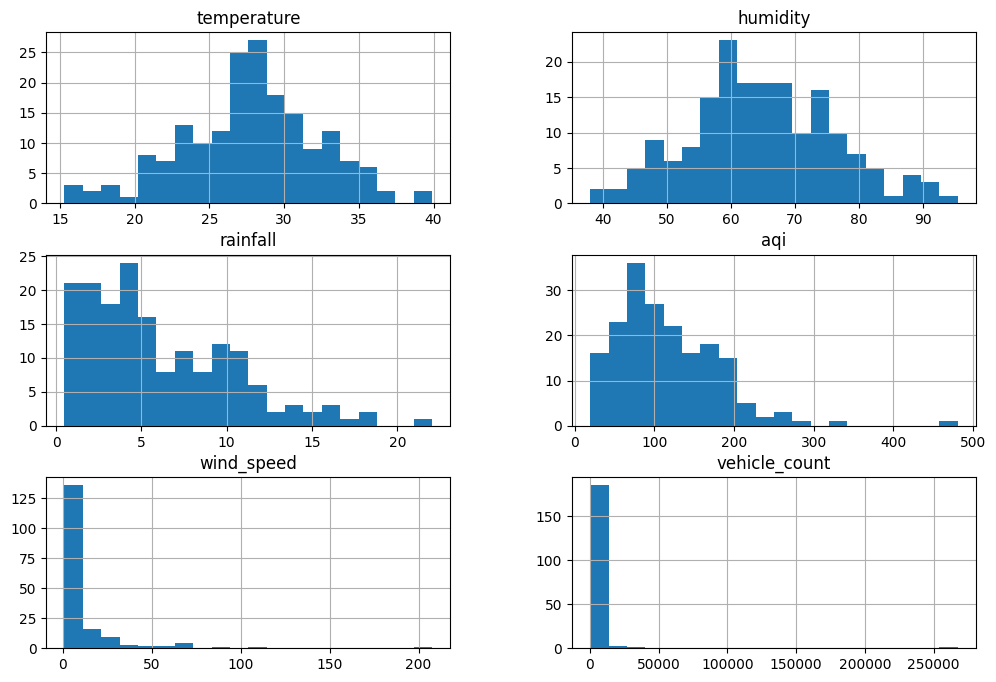

In [10]:
df.hist(figsize=(12, 8), bins=20)
plt.show()

B2Imputation


For temprature mean(symmetric)
For humidity median(it is skewed )
rainfall median(right skewed)
aqi median(right skewed)
wind speed much much right skewed so median 
vechile count too highly right skewed therefore median 




In [11]:
df["temperature"] = df["temperature"].fillna(df["temperature"].mean())
print(df["temperature"])

0      27.9
1      24.7
2      16.0
3      27.0
4      25.8
       ... 
195    22.7
196    34.1
197    26.1
198    33.5
199    30.3
Name: temperature, Length: 200, dtype: float64


In [12]:
df["humidity"] = df["humidity"].fillna(df["humidity"].median())
print(df["humidity"])

0      48.2
1      61.0
2      60.5
3      56.7
4      64.6
       ... 
195    67.8
196    38.0
197    65.3
198    63.1
199    80.5
Name: humidity, Length: 200, dtype: float64


In [13]:
before = df["rainfall"].copy()
df["rainfall"] = df["rainfall"].fillna(df["rainfall"].median())
print(df["rainfall"])

0      1.71
1      4.87
2      8.24
3      1.62
4      4.24
       ... 
195    2.64
196    4.87
197    4.87
198    4.87
199    5.44
Name: rainfall, Length: 200, dtype: float64


In [14]:
df["aqi"] = df["aqi"].fillna(df["aqi"].median())
print(df["aqi"])


0       40.0
1       81.2
2      221.6
3      149.3
4      196.7
       ...  
195    117.6
196    149.0
197     76.6
198    181.9
199     88.9
Name: aqi, Length: 200, dtype: float64


In [15]:
df["wind_speed"] = df["wind_speed"].fillna(df["wind_speed"].median())
print(df["wind_speed"])

0       1.55
1      14.61
2       1.20
3      16.14
4       3.87
       ...  
195     5.96
196     1.70
197     2.15
198     3.25
199     6.64
Name: wind_speed, Length: 200, dtype: float64


In [16]:
df["vehicle_count"] = df["vehicle_count"].fillna(df["vehicle_count"].median())
print(df["vehicle_count"])

0      464.0
1      614.0
2      131.0
3      803.0
4      190.0
       ...  
195    174.0
196    404.0
197    348.0
198    911.0
199    138.0
Name: vehicle_count, Length: 200, dtype: float64


In [17]:
print(df.isnull().sum())

temperature      0
humidity         0
rainfall         0
aqi              0
wind_speed       0
vehicle_count    0
dtype: int64


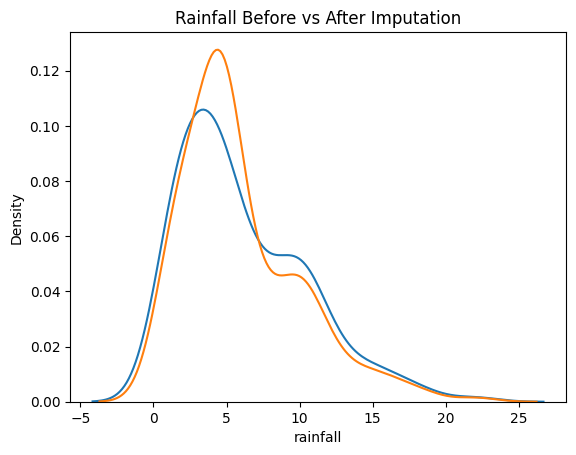

In [18]:
sns.kdeplot(before)
sns.kdeplot(df["rainfall"])
plt.title("Rainfall Before vs After Imputation")
plt.show()

B.3  Histograms


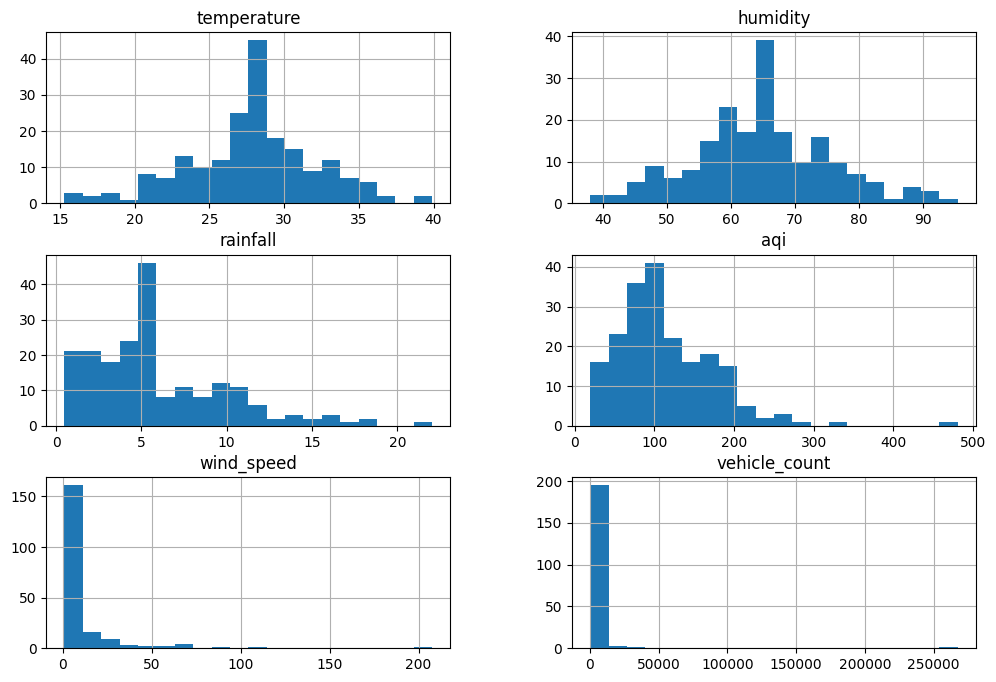

In [19]:
df.hist(figsize=(12, 8),bins=20)
plt.show()

Temprature - Nearly symmetric and kind of follow normal distribution 
Humidity - symmetic and less values on right side
Rainfall - positive skew have a right tail kind of exponential 
Aqi-positive skew have few outliners 
Wind speed- positive skew values mostly at lower end 
vechile count - highly +ve skewed

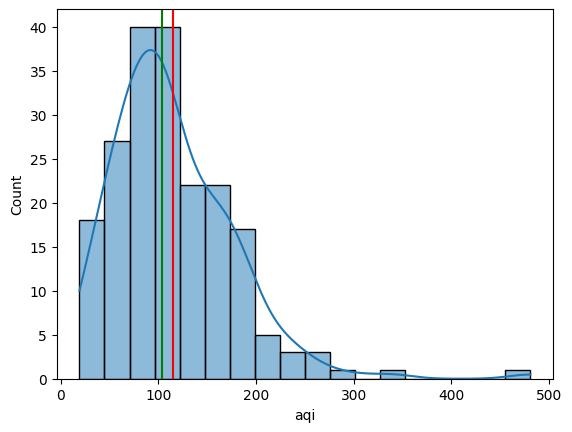

In [20]:
sns.histplot(df["aqi"], kde=True)

plt.axvline(df["aqi"].mean(), color="red")
plt.axvline(df["aqi"].median(), color="green")

plt.show()

Aqi is right skew as mean is right as to median mean high aqi value takes mean to right 

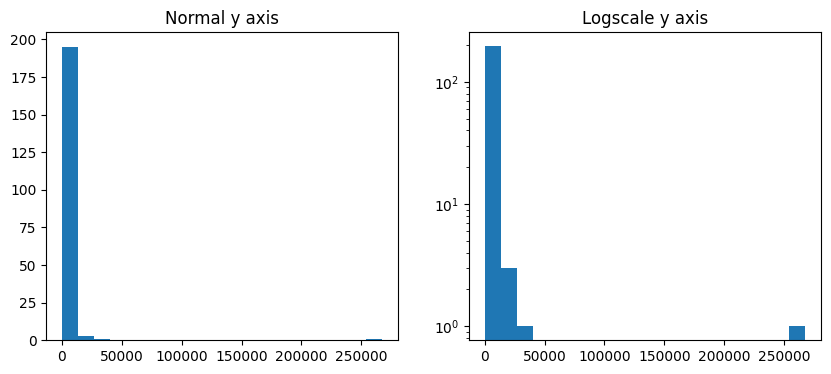

In [21]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.hist(df["vehicle_count"], bins=20)
plt.title("Normal y axis")
plt.subplot(1,2,2)
plt.hist(df["vehicle_count"], bins=20)
plt.yscale("log")
plt.title("Logscale y axis")

plt.show()

The log scale shows that most vehicle counts are low and only a few are very high.

B.4  Box Plots and Outlier Detection

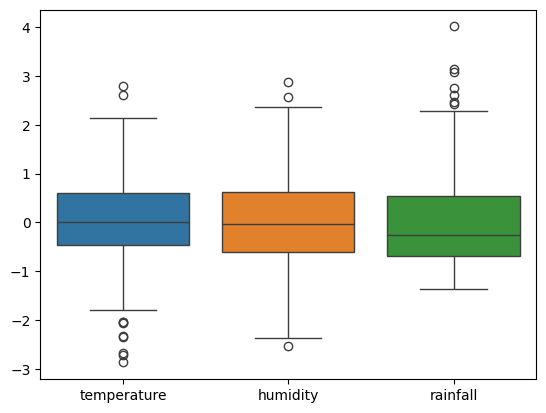

In [22]:
z_data = df[["temperature", "humidity", "rainfall"]].apply(zscore)
sns.boxplot(data=z_data)
plt.show()

In [23]:
# sns.distplot(df)

Rainfall has the most outlier points right skewed data usually has more extreme values

In [24]:
Q1 = df["wind_speed"].quantile(0.25)
Q3 = df["wind_speed"].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df["wind_speed"] < Q1 - 1.5*IQR) | (df["wind_speed"] > Q3 + 1.5*IQR)]

print(len(outliers))
print(outliers)

24
     temperature  humidity  rainfall    aqi  wind_speed  vehicle_count
5       36.70000     51.80     10.04  104.0       22.69         1391.0
7       31.00000     58.00      4.95   62.2       22.08          397.0
18      27.76978     82.00     10.80  133.2       20.89          497.0
26      22.70000     53.30      4.87   57.9       92.69          801.0
45      29.00000     48.10      4.87   98.6       64.23          148.0
53      20.60000     56.90      0.66  104.0       25.13          977.0
72      20.30000     55.90      4.87  128.5      207.60         4036.0
81      27.76978     71.40      1.18  184.4       29.09          205.0
89      28.20000     59.90      4.79  197.3       23.34          581.0
90      26.60000     61.40     10.61  146.2       30.28          497.0
91      20.80000     64.35      6.35  108.9       69.98          205.0
98      28.90000     64.35      9.69  127.7       68.94          859.0
107     24.60000     59.80     12.24  480.9       39.21          497.0
109

An extreme wind speed city day represet highh spedd wind

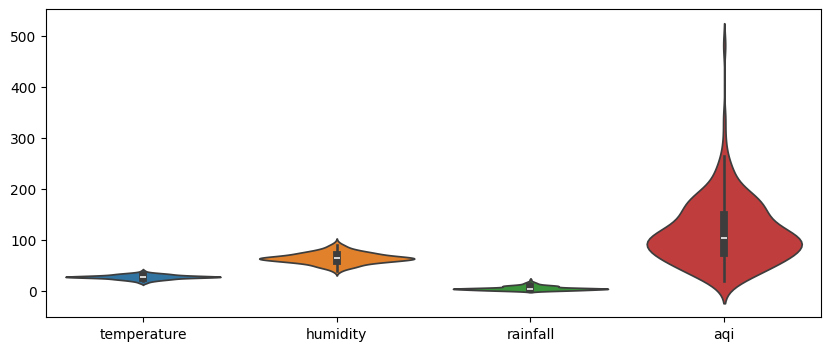

In [25]:
plt.figure(figsize=(10,4))
sns.violinplot(data=df[["temperature", "humidity", "rainfall", "aqi"]])
plt.show()

Temperature and Humidity are close to a Normal distribution
Rainfall and AQI are Gamma and right skewed.


B.5  Scatter, Pair Plot, and Correlation

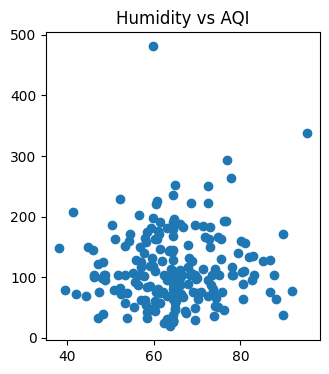

In [26]:

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.scatter(df["humidity"], df["aqi"])
plt.title("Humidity vs AQI")
plt.show()

not clear 

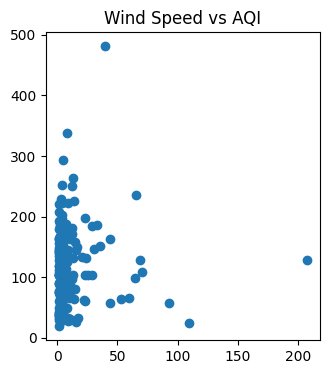

In [27]:
plt.figure(figsize=(12,4))
plt.subplot(1,3,2)
plt.scatter(df["wind_speed"], df["aqi"])
plt.title("Wind Speed vs AQI")
plt.show()


not clear

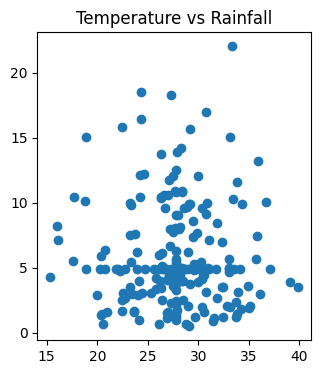

In [28]:
plt.figure(figsize=(12,4))
plt.subplot(1,3,3)
plt.scatter(df["temperature"], df["rainfall"])
plt.title("Temperature vs Rainfall")
plt.show()

some -ve trend

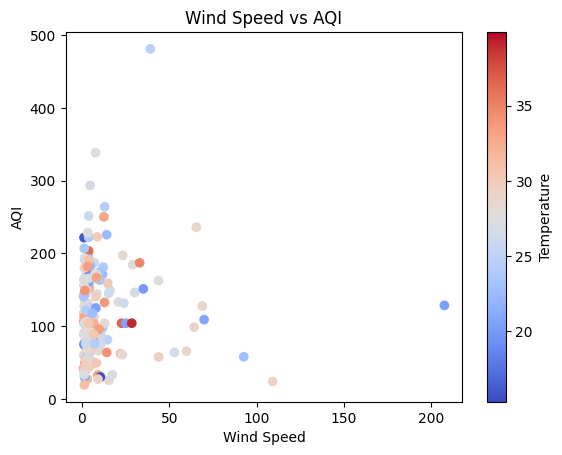

In [29]:
plt.scatter(df["wind_speed"], df["aqi"], c=df["temperature"], cmap="coolwarm")
plt.colorbar(label="Temperature")
plt.xlabel("Wind Speed")
plt.ylabel("AQI")
plt.title("Wind Speed vs AQI")
plt.show()

Stronger winds clear out air pollution

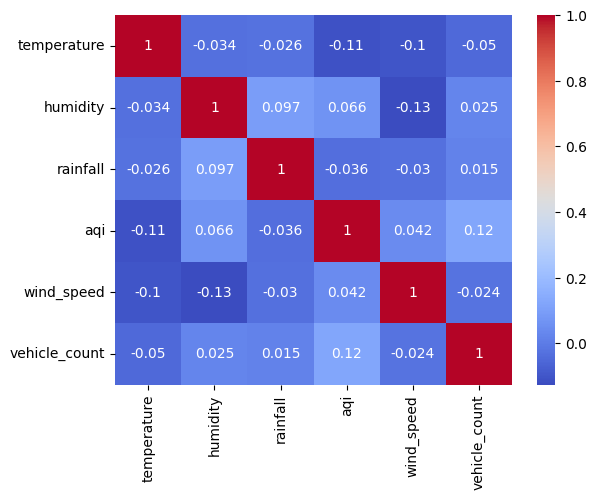

               temperature  humidity  rainfall       aqi  wind_speed  \
temperature       1.000000 -0.033814 -0.025533 -0.113133   -0.102993   
humidity         -0.033814  1.000000  0.096534  0.066042   -0.126369   
rainfall         -0.025533  0.096534  1.000000 -0.036444   -0.029703   
aqi              -0.113133  0.066042 -0.036444  1.000000    0.041908   
wind_speed       -0.102993 -0.126369 -0.029703  0.041908    1.000000   
vehicle_count    -0.050124  0.025155  0.015210  0.120152   -0.024353   

               vehicle_count  
temperature        -0.050124  
humidity            0.025155  
rainfall            0.015210  
aqi                 0.120152  
wind_speed         -0.024353  
vehicle_count       1.000000  


In [30]:
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.show()
print(df.corr())

B.6  Take-Home (Submit with Notebook)

In [31]:
df_dropped = temp.dropna()
df_imputed = df

In [32]:
print(df_dropped.shape)
print(df_imputed.shape)

(101, 6)
(200, 6)


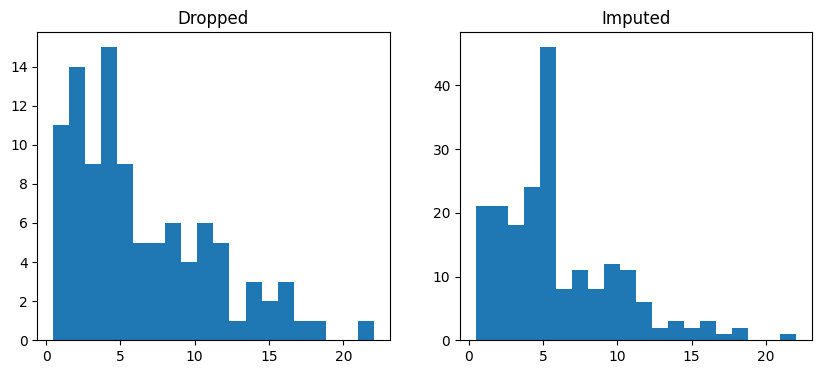

In [33]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.hist(df_dropped["rainfall"], bins=20)
plt.title("Dropped")

plt.subplot(1,2,2)
plt.hist(df_imputed["rainfall"], bins=20)
plt.title("Imputed")

plt.show()

In [34]:
print("Rows lost",len(df_imputed) -len(df_dropped))

Rows lost 99


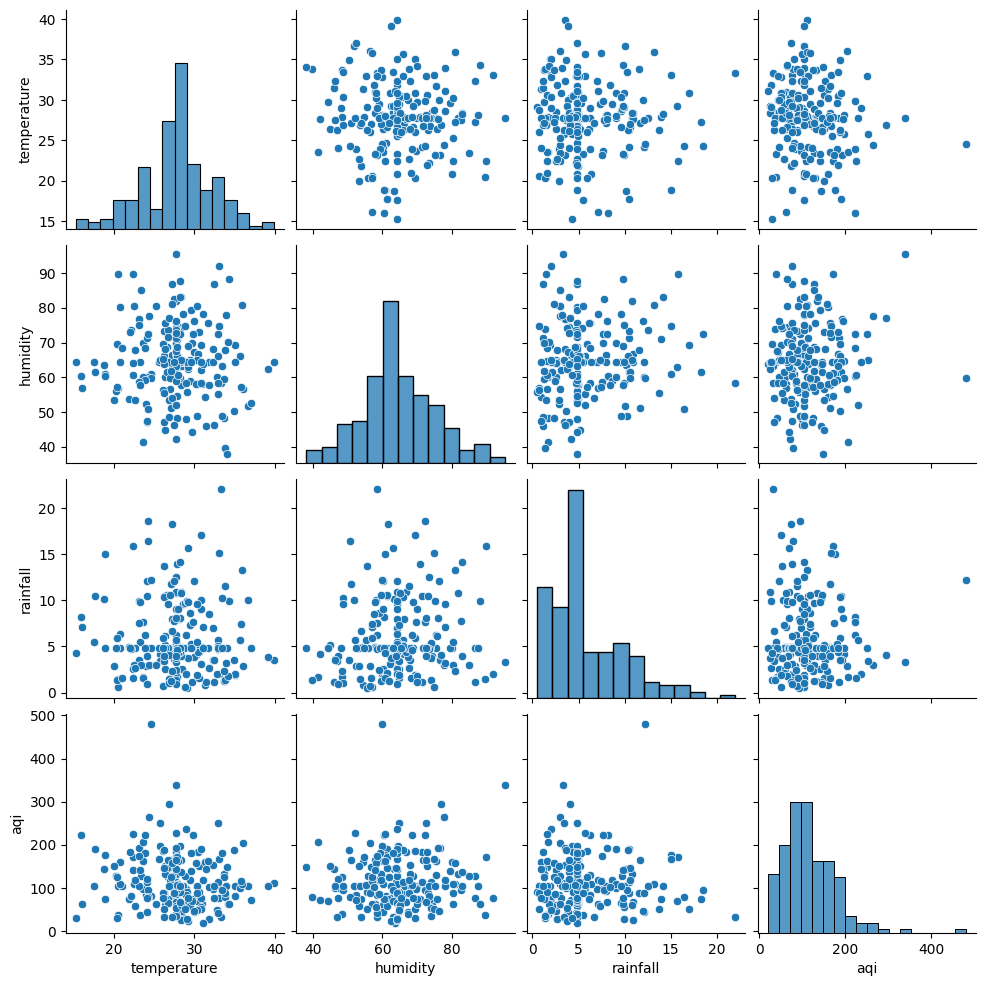

In [35]:
sns.pairplot(df[["temperature", "humidity", "rainfall", "aqi"]])
plt.show()

i choose this cause it was in tutorial and also in documentation The pair plot shows the distribution of each variable and the relationship between every pair of variables it makes easy to plot trends